In [1]:
import torch
from torch import nn

In [2]:
# weight 와 bias 확인
x = torch.randn(100, 3)
layer = nn.Linear(3,5)
print(x.shape)
print(layer)
print(layer(x).shape)
print(layer.weight) # 랜덤한 (5,3)의 초기 weight
print(layer.bias)   # 랜덤한 (5,)의 초기 bias

torch.Size([100, 3])
Linear(in_features=3, out_features=5, bias=True)
torch.Size([100, 5])
Parameter containing:
tensor([[-0.1411,  0.2248,  0.1890],
        [-0.0797, -0.4851,  0.3361],
        [ 0.1792,  0.4363, -0.3141],
        [ 0.1982, -0.3685,  0.3880],
        [ 0.1535, -0.3823, -0.4988]], requires_grad=True)
Parameter containing:
tensor([-0.5408,  0.1840, -0.1447, -0.0365,  0.3997], requires_grad=True)


In [3]:
x = torch.randn(2,5)
layer = nn.ReLU()   # 음수값은 0으로 변환
print(x)
print(layer(x))

tensor([[ 0.7176, -0.3596, -1.1225,  0.3217,  0.1620],
        [-1.2923, -1.7890, -2.4467, -0.0113, -0.7890]])
tensor([[0.7176, 0.0000, 0.0000, 0.3217, 0.1620],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000]])


In [4]:
# 초기 weight와 bias가 랜덤이 아닌 layer
layer = nn.BatchNorm1d(3)   # 표준편차가 1이고 평균이 0인 표준화
print(layer.weight)
print(layer.bias)

x = torch.randn(5,3)
print(x)
print(layer(x))
print(layer(x).mean(dim=0)) # 평균이 0임을 확인
print(layer(x).std(dim=0, unbiased=False))  # False(모평균: 뮤 사용), True(표본평균: x-bar 사용)

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)
Parameter containing:
tensor([0., 0., 0.], requires_grad=True)
tensor([[-1.4076,  0.0958, -0.5322],
        [-0.9724, -1.4594,  0.1757],
        [-1.5262, -1.9853,  2.0965],
        [ 1.2740, -0.4817, -0.8184],
        [-0.8932, -0.4438,  0.4457]])
tensor([[-0.6895,  1.2580, -0.7898],
        [-0.2623, -0.7999, -0.0958],
        [-0.8059, -1.4959,  1.7870],
        [ 1.9422,  0.4938, -1.0702],
        [-0.1846,  0.5440,  0.1688]], grad_fn=<NativeBatchNormBackward0>)
tensor([ 0.0000e+00, -8.3447e-08,  0.0000e+00], grad_fn=<MeanBackward1>)
tensor([1.0000, 1.0000, 1.0000], grad_fn=<StdBackward0>)


In [5]:
layer = nn.LayerNorm(3)
print(layer.weight)
print(layer.bias)

x = torch.randn(5,3)
print(x)
print(layer(x))
print(layer(x).mean(dim=1))     # layerNorm에서는 dim=1
print(layer(x).std(dim=1, unbiased=False))

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)
Parameter containing:
tensor([0., 0., 0.], requires_grad=True)
tensor([[ 0.3594, -0.0737,  1.0667],
        [ 1.2415, -0.1795,  0.1878],
        [ 1.4583, -0.8400,  0.6268],
        [-1.2202,  0.4080,  1.9774],
        [ 0.4908, -1.0032, -0.6304]])
tensor([[-0.1945, -1.1159,  1.3103],
        [ 1.3697, -0.9897, -0.3799],
        [ 1.0980, -1.3209,  0.2229],
        [-1.2322,  0.0150,  1.2172],
        [ 1.3730, -0.9801, -0.3929]], grad_fn=<NativeLayerNormBackward0>)
tensor([ 0.0000e+00,  0.0000e+00, -1.9868e-08, -7.9473e-08,  4.9671e-08],
       grad_fn=<MeanBackward1>)
tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<StdBackward0>)


In [6]:
layer = nn.BatchNorm2d(3)
print(layer.weight)
print(layer.bias)

x = torch.randn(5,3,32,32)
print(layer(x).mean(dim=(0,2,3)))   # 각 채널별 평균
# dim은 몬티홀의 문제처럼 구하고 싶은 차원의 번호만 제외하는 방식이었군요
print(layer(x).std(dim=(0,2,3), unbiased=False))

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)
Parameter containing:
tensor([0., 0., 0.], requires_grad=True)
tensor([-1.7881e-08, -6.2399e-09, -1.4901e-08], grad_fn=<MeanBackward1>)
tensor([1.0000, 1.0000, 1.0000], grad_fn=<StdBackward0>)


In [7]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms, datasets
import matplotlib.pyplot as plt
import numpy as np
import os
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [8]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
new_model_train = True

model_type = 'CNN_deep'
dataset = 'CIFAR10'

save_dir = 'results'
os.makedirs(save_dir, exist_ok=True)

save_model_path = f'{save_dir}/{model_type}_{dataset}.pt'

In [ ]:
# def square(x):
#     return x**2

In [17]:
transform_train = transforms.Compose([
    # ----------- 이미지 size 및 영역 조절 ---------------
    # transforms.Resize(size=(20,20)),    # 보간법(NOTE interpolation)에 따른 픽셀 값 계산
    # transforms.CenterCrop(size=(20,20,)),   # 가운데를 중심으로 외곽을 잘라냄
    # transforms.RandomCrop(size=(20,20)),    # random한 위치를 중심으로 외곽을 자름
    # # 추가 기준 (Anti-aliasing): 이미지를 축소할 때 픽셀이 뭉개지거나 물결무늬(Moire)가 생기는 것을 막기 위해 
    # # antialias=True가 기본 적용 
    # # 이 경우 축소 비율에 맞춰 주변 픽셀들을 먼저 부드럽게 블러(가우시안 필터 등) 처리한 뒤 위 보간법을 적용
    # transforms.Pad(6),  # 원본 사이즈를 유지하기 위해 패드size 만큼의 검은색 테두리 생성

    # ----------- 조건부 이미지 변환 ---------------------
    # transforms.RandomApply(
    #     nn.ModuleList([
    #         transforms.CenterCrop(size=(20,20)),
    #         transforms.Pad(6)
    #     ]), p = 0.5 # 50% 의 확률로 centercrop과 pad 적용
    # ),

    # transforms.RandomResizedCrop(
    #     size= (32, 32),     # 최종 이미지 크기
    #     scale= (0.3, 1),    # 원본 이미지 면적의 30% ~ 100% 범위를 crop
    #     ratio=(0.3, 1.7)    # crop 영역의 가로/세로 비율 범위
    # ),

    # ------------ 색상 및 밝기 조절 --------------------
    # transforms.RandomGrayscale(p=.5),
    # transforms.ColorJitter(
    #     brightness=0.3, # 밝기
    #     contrast= 0.3,  # 대비
    #     saturation=0.5, # 채도
    #     hue= 0.15       # 색조
    # ),
    # transforms.RandomAutocontrast(p=.5),    # 자동으로 명암 대비를 높이는 효과
    # transforms.RandomEqualize(p=0.5),   # 각 채널의 히스토그램을 개별적으로 처리, 평활화(특정 밝기 이미지의 대비 강조)
    # transforms.RandomInvert(p=0.5),     # 색상 반전
    # transforms.RandomSolarize(threshold=200, p=0.5),    # 밝은 영역의 색상을 반전시켜 특별한 명암을 표현
    # threshold <= 255 : rgb 색상값
    # transforms.RandomPosterize(bits=1, p=1),   # bits: 8bit(256개)의 색상 수를 bit(2^n)로 줄여서 표현

    # ------------ 선명도 및 흐림 정도 ------------------
    # transforms.GaussianBlur(    # 정규분포 값에 따라 흐림 처리
    #     kernel_size=(5,5),
    #     sigma=(0.12,2)
    # ),  
    # transforms.RandomAdjustSharpness(
    #     sharpness_factor = 2,   # 1보다 크면 선명도 증가, 1보다 작으면 선명도 감소
    #     p=1
    # ),

    # ------------ 방향 및 위치 변환 ----------------------
    # transforms.RandomHorizontalFlip(p=1),   # 좌우 반전
    # transforms.RandomVerticalFlip(p=1,),     # 상하 반전
    # transforms.RandomRotation(degrees=(0,45)),
    # transforms.RandomAffine(
    #     degrees= (0,90),
    #     translate= (0.1, 0.3),  # 0.1 에서 0.3 사이를 회전
    #     scale= (0.5, 1.2)
    # ),  # 센서의 위치와 보는 방향의 변화도 학습시키기 위함
    # transforms.RandomPerspective(
    #     distortion_scale=0.6,
    #     p=1    ),   # 센서가 받아들이는 이미지의 원근감의 변화를 학습

    # ------------ 자동 데이터 증강 -----------------------
    # AutoAugment: Learning Augmentation Strategies from Data (CVPR 2019)
    # CIFAR10, IMAGENET, SVHN 3가지 데이터셋의 최적화 증강과 관련된 논문
    # 딥러닝 모델의 성능을 높이기 위해 기존의 CIFAR-10 이미지에 다양한 변형을 가해 학습 데이터의 양을 인위적으로 늘리는 기법
    # AutoAugmentPolicy.CIFAR10 : randomcrop, randomhorizantal flip, cutout, colorjitter 을 사용

    # transforms.AutoAugment(transforms.AutoAugmentPolicy.CIFAR10),
    # transforms.AutoAugment(transforms.AutoAugmentPolicy.SVHN),

    # transforms.RandAugment(),   # 랜덤한 증강 적용
    # transforms.TrivialAugmentWide(), # 한 데이터에 하나의 랜덤한 증강을 적용
    # transforms.AugMix(),    # 여러 증강기법을 무작위로 선택하고 혼합하여 적용

    transforms.ToTensor(),   # 1. PIL 이미지 또는 NUMPY 배열을 Tensor변환
                            # 2. 이미지 데이터 형태 변환 (H,W,C) -> (C,H,W)
                            # 3. 픽셀값 0~255의 값을 0~1 범위의 실수형으로 변환


    # ------------- 자동 이미지 제거 ----------------------
    # transforms.RandomErasing(
    #     p=0.5,
    #     scale=(0.03, 0.3),
    #     ratio=(0.3, 3.3)
    # )

    # ------------- 사용자 정의 함수 호출 ------------------
    # transforms.Lambda(square)
    # transforms.Lambda(lambda x:x**2)
    # lambda x: x ** 2

    # -------------  표준화  -----------------------------
    transforms.Normalize(
        (0.485, 0.456, 0.406),  # 원하는 RGB의 평균
        (0.229, 0.224, 0.225)   # 원하는 RGB의 표준편차
    )
    
    # 내가 정의한 함수가 있다면 ToTensor() 다음에 삽입
])
transform_test = transforms.ToTensor()

train_DS = datasets.CIFAR10(root='data', train=True, transform=transform_train, download=True)
test_DS = datasets.CIFAR10(root='data', train=False, transform=transform_test, download=True)

train_DL = DataLoader(train_DS, batch_size= BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=True)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8952821..2.1171243].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1007793..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.4671633..2.3611329].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.8506721..2.6051416].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.4842881..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


image size= torch.Size([3, 32, 32])
image size= torch.Size([3, 32, 32])


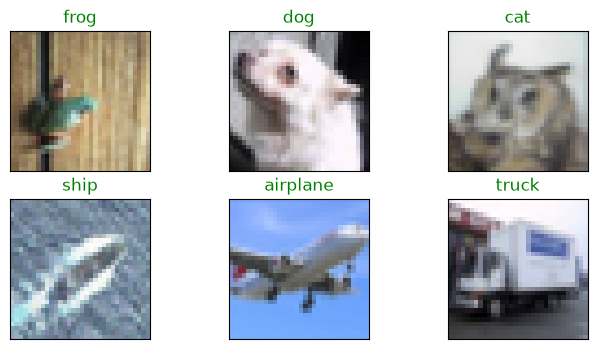

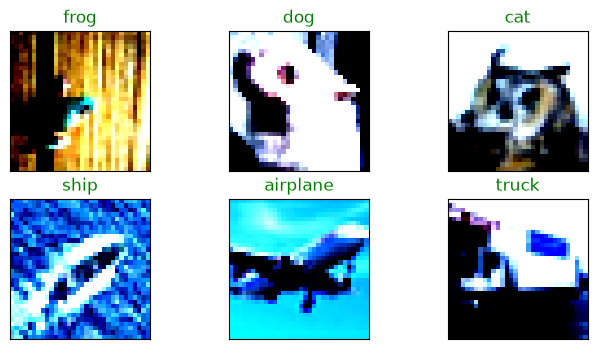

In [18]:
from PIL import Image   # Python Image Library/ Image = numpy array 이미지변환

def im_plot(x_numpy, y_batch, transform):  # 호출할 때 transform.compose의 변환이 실행됨
    plt.figure(figsize=(8,4))
    for idx in range(6):
        im = Image.fromarray(x_numpy[idx])
        im = transform(im)

        plt.subplot(2,3, idx+1, xticks=[], yticks=[])
        plt.imshow(im.permute(1,2,0))
        true_class = test_DS.classes[y_batch[idx]]
        plt.title(true_class, color='g')
    print(f'image size= {im.shape}')

idx = torch.randint(0,10000,(6,))
x_batch = test_DS.data[idx]
target = torch.tensor(test_DS.targets)

y_batch = target[idx]
im_plot(x_batch, y_batch, transform_test)   # 원본(32,32)
im_plot(x_batch, y_batch, transform_train)  # Resize(20,20)

In [ ]:
from torchvision.transforms import functional as F
from torchvision.transforms.autoaugment import _apply_op

class TrivialAugmentWithInfo(transforms.TrivialAugmentWide):

    def forward(self, img):
        # 이미지 채널 수 확인
        channels, _, _ = F.get_dimensions(img)

        fill = self.fill
        if isinstance(img, torch.Tensor):
            if isinstance(fill, (int, float)):
                fill = [float(fill)] * channels
            elif fill is not None:
                fill = [float(f) for f in fill]

        # 증강 종류 무작위 선택
        op_meta = self._augmentation_space(self.num_magnitude_bins)
        op_index = int(torch.randint(len(op_meta), (1,)).item())
        op_name = list(op_meta.keys())[op_index]

        # 증강 강도 무작위 선택
        magnitudes, signed = op_meta[op_name]

        magnitude = (
            float(magnitudes[torch.randint(len(magnitudes), (1,))].item())
            if magnitudes.ndim > 0 else 0.0
        )

        if signed and bool(torch.randint(2, (1,)).item()):
            magnitude *= -1.0

        # 선택된 증강 정보 저장
        self.op_name = op_name
        self.magnitude = magnitude

        # 실제 증강 적용
        return _apply_op(
            img, op_name, magnitude,
            interpolation=self.interpolation,
            fill=fill
        )

In [ ]:
augment = TrivialAugmentWithInfo()

def im_plot(x_numpy, y_batch, transform):
    plt.figure(figsize=(10, 5))

    for idx in range(6):
        im = Image.fromarray(x_numpy[idx])
        im = transform(im)

        # 증강 종류 및 강도 확인
        if augment in getattr(transform, 'transforms', []):
            op_name = augment.op_name
            magnitude = augment.magnitude
            aug_info = f'{op_name} ({magnitude:.2f})'
        else:
            aug_info = 'Original'

        plt.subplot(2, 3, idx+1, xticks=[], yticks=[])
        plt.imshow(im.permute(1, 2, 0))

        true_class = test_DS.classes[y_batch[idx]]

        plt.title(
            f'{true_class}\n{aug_info}',
            color='g' if aug_info == 'Original' else 'r'
        )

    plt.tight_layout()
    plt.show()
    print(f'image size = {im.shape}')

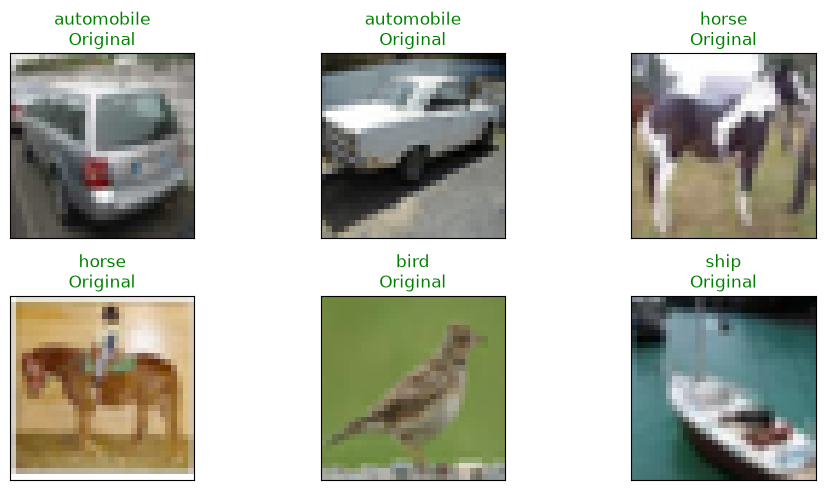

image size = torch.Size([3, 32, 32])


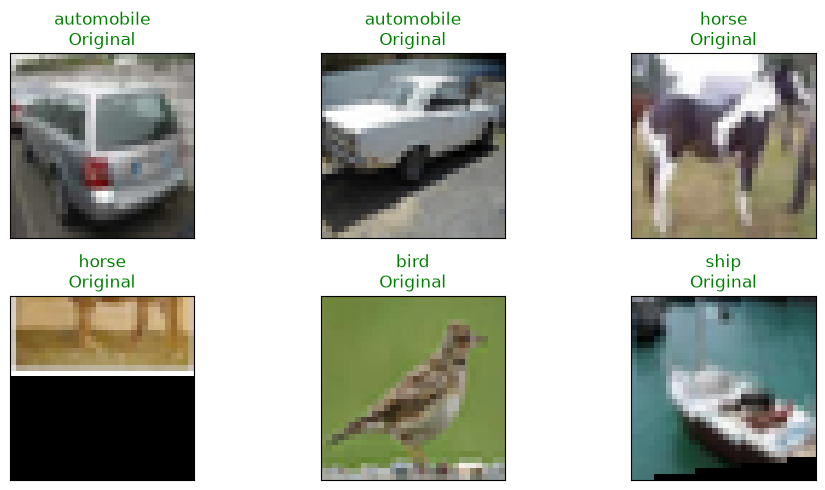

image size = torch.Size([3, 32, 32])


In [ ]:
idx = torch.randint(0, 10000, (6,))
x_batch = test_DS.data[idx]
target = torch.tensor(test_DS.targets)
y_batch = target[idx]

im_plot(x_batch, y_batch, transform_test)
im_plot(x_batch, y_batch, transform_train)